---

# Tugas Besar 2 IF3170 Inteligensi Artifisial

*This notebook is the assignment template. Each group works on its own copy, and cells or sections may be added as needed.*

## Group 32 — FrontierFolly

- Ega Luthfi Rais (13524115)
- Awan
- Ahmad
- Jojo
- Faris


---

## Table of Contents

1. [**Introduction**](#1)
2. [**Initialization**](#2)
3. [**Data Understanding (Optional)**](#3)
4. [**Training and Validation Split**](#4)
5. [**Data Preparation**](#5)
6. [**Preparation Pipeline**](#6)
7. [**Modeling and Validation**](#7)
8. [**Comparison with scikit-learn**](#8)
9. [**Saving and Loading Models**](#9)
10. [**Kaggle Submission**](#10)
11. [**Error Analysis**](#11)


---

# Introduction <a name="1"></a>

---

Notebook ini memakai satu pipeline data yang sama untuk semua model. Setiap
statistik preprocessing di-fit pada training split saja, lalu validation dan
test di-transform dengan objek yang sudah fit. Model from scratch diimpor dari
`src.models`.


Dataset berisi pemesanan hotel dengan target `is_canceled`. Tujuannya
memprediksi apakah sebuah pemesanan akan dibatalkan berdasarkan atribut
pemesanan, tamu, dan kanal booking.


Membangun lima classifier from scratch (KNN, DTL, Logistic Regression, SVM,
Naive Bayes), memvalidasinya dengan macro F1, membandingkannya dengan
scikit-learn, lalu menghasilkan satu submission Kaggle.


Metrik utama adalah **macro F1**. Dataset tidak seimbang (sekitar 32,77%
positif), sehingga akurasi saja menyesatkan: macro F1 memberi bobot yang sama
untuk kedua kelas.


- `train.csv`: 27.373 baris, 19 kolom (18 fitur + `is_canceled`)
- `test.csv`: 6.844 baris, 18 kolom
- `sample_submission.csv`: `id`, `is_canceled`


Semua angka di notebook ini memakai `SEED = 42` dan split stratified 80/20.


1. Baca data dan lakukan EDA singkat.
2. Split train/validation secara stratified sebelum preprocessing.
3. Bangun pipeline: cleaning, imputasi + flag missing, feature engineering,
   one-hot, scaling, seleksi fitur.
4. Latih lima model from scratch dan hitung macro F1 di validation.
5. Bandingkan dengan scikit-learn dan simpan model.
6. Latih ulang model terbaik pada seluruh train dan buat submission.


---

# Initialization <a name="2"></a>

---

This section prepares the environment, the settings, and the data files.

## Environment Setup

The following cell lists the base libraries. The install line is commented by default.

In [1]:
# %pip install -q numpy pandas scikit-learn matplotlib seaborn


## Import Libraries

Every import of the notebook is kept in this cell.

In [2]:
import json
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.preprocessing import OneHotEncoder, StandardScaler

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.data.united_setup import united_setup
from src.models import DecisionTree, KNN, LogisticRegression, NaiveBayes, SVM

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")


## Settings

Paths and shared constants are kept in this class.

In [3]:
class Settings:
    SEED = 42
    DATA_DIR = ROOT / "data" / "raw"
    PREP_DIR = ROOT / "output" / "prepared"
    OUTPUT_DIR = ROOT / "output"
    TARGET = "is_canceled"
    ID_COL = "id"

CFG = Settings()
CFG.OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


## Seed Everything

A fixed seed keeps the results reproducible.

In [4]:
def seed_everything(seed: int):
    import os
    import random

    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)

seed_everything(CFG.SEED)


## Load Dataset

The competition files are read here. The `id` column stays as text because some values resemble numbers.

In [5]:
train_path = CFG.DATA_DIR / "train.csv"
test_path = CFG.DATA_DIR / "test.csv"
if not train_path.exists() or not test_path.exists():
    raise FileNotFoundError(
        "Taruh train.csv, test.csv, dan sample_submission.csv di data/raw/."
    )

train_df = pd.read_csv(train_path, dtype={CFG.ID_COL: str})
test_df = pd.read_csv(test_path, dtype={CFG.ID_COL: str})
sample_sub = pd.read_csv(CFG.DATA_DIR / "sample_submission.csv", dtype={CFG.ID_COL: str})

print(f"Train: {train_df.shape}  Test: {test_df.shape}  Sample: {sample_sub.shape}")


Train: (27373, 19)  Test: (6844, 18)  Sample: (6844, 2)


---

# Data Understanding (Optional) <a name="3"></a>

---

Data understanding builds the knowledge that later preparation decisions rest on.

## Describe Data

This part covers the size, the attribute types, and the meaning of each column.

In [6]:
print("Shape")
display(pd.DataFrame({"train": train_df.shape, "test": test_df.shape}, index=["rows", "columns"]))

print("\nTipe data")
display(train_df.dtypes.to_frame("dtype").T)

print("\nDistribusi target")
display((train_df[CFG.TARGET].value_counts(normalize=True) * 100).round(2).to_frame("percent"))

print("\nStatistik numerik")
display(train_df.describe().T.round(3))


Shape


,train,test
rows,27373,6844
columns,19,18



Tipe data


,id,num_adults,num_children,weekend_nights,weekday_nights,meal_package,needs_parking,room_category,days_before_arrival,arrival_year,arrival_month,arrival_day,booking_channel,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,is_canceled
dtype,object,float64,float64,int64,int64,object,float64,object,float64,int64,int64,int64,object,int64,int64,int64,float64,float64,int64



Distribusi target


,percent
is_canceled,
0,67.23
1,32.77



Statistik numerik


,count,mean,std,min,25%,50%,75%,max
num_adults,26564.0,1.845,0.518,0.0,2.0,2.0,2.0,4.0
num_children,24338.0,0.117,0.426,0.0,0.0,0.0,0.0,10.0
weekend_nights,27373.0,0.815,0.875,0.0,0.0,1.0,2.0,7.0
weekday_nights,27373.0,2.207,1.422,0.0,1.0,2.0,3.0,17.0
needs_parking,26291.0,0.030,0.171,0.0,0.0,0.0,0.0,1.0
days_before_arrival,26250.0,85.379,85.970,0.0,17.0,58.0,126.0,448.0
arrival_year,27373.0,2023.820,0.384,2023.0,2024.0,2024.0,2024.0,2024.0
arrival_month,27373.0,7.400,3.075,1.0,5.0,8.0,10.0,12.0
arrival_day,27373.0,15.538,8.773,1.0,8.0,16.0,23.0,31.0
is_returning_guest,27373.0,0.025,0.157,0.0,0.0,0.0,0.0,1.0


## Explore Data

This part covers distributions and relationships between attributes.

,missing,percent
num_children,3035,11.09
special_requests,2500,9.13
nightly_rate_idr,2038,7.45
meal_package,1760,6.43
days_before_arrival,1123,4.10
needs_parking,1082,3.95
room_category,1002,3.66
num_adults,809,2.96


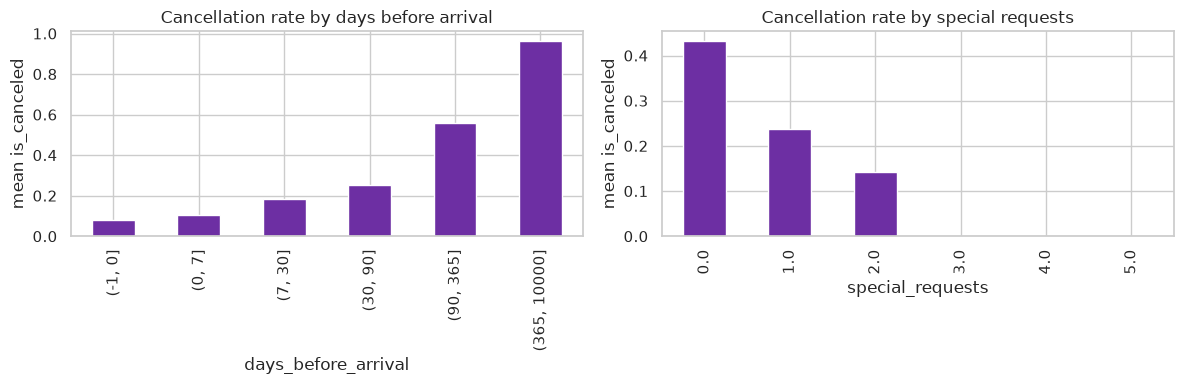

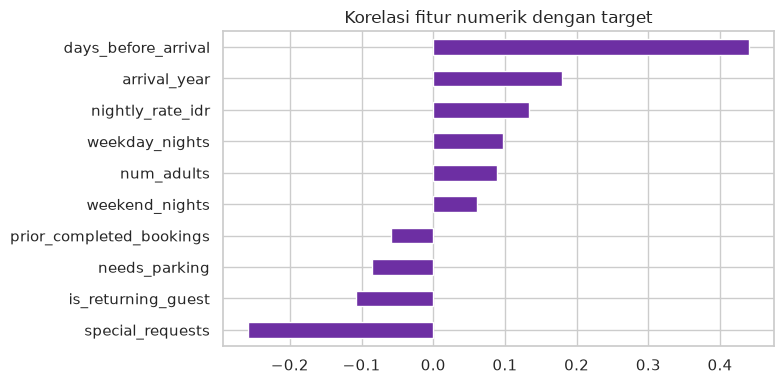

In [7]:
missing = train_df.isna().sum().to_frame("missing")
missing["percent"] = (missing["missing"] / len(train_df) * 100).round(2)
display(missing[missing["missing"] > 0].sort_values("percent", ascending=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
train_df.groupby(pd.cut(train_df["days_before_arrival"], bins=[-1, 0, 7, 30, 90, 365, 10000]))[
    CFG.TARGET
].mean().plot(kind="bar", ax=axes[0], color="#6d2fa3")
axes[0].set_title("Cancellation rate by days before arrival")
axes[0].set_ylabel("mean is_canceled")

train_df.groupby("special_requests")[CFG.TARGET].mean().plot(
    kind="bar", ax=axes[1], color="#6d2fa3"
)
axes[1].set_title("Cancellation rate by special requests")
axes[1].set_ylabel("mean is_canceled")
plt.tight_layout()
plt.show()

corr = (
    train_df.select_dtypes("number")
    .corr()[CFG.TARGET]
    .drop(CFG.TARGET)
    .sort_values(key=abs, ascending=False)
    .head(10)
)
corr.sort_values().plot(kind="barh", figsize=(8, 4), color="#6d2fa3")
plt.title("Korelasi fitur numerik dengan target")
plt.tight_layout()
plt.show()


## Verify Data Quality

This part covers completeness, consistency, and the validity of values.

In [8]:
features = [c for c in train_df.columns if c not in (CFG.ID_COL, CFG.TARGET)]
duplicates = train_df.duplicated(subset=features).sum()

print(f"Baris duplikat fitur : {duplicates}")
print(f"num_adults == 0      : {(train_df['num_adults'] == 0).sum()}")
print(f"total nights == 0    : {((train_df['weekend_nights'] + train_df['weekday_nights']) == 0).sum()}")
print(f"nightly_rate_idr == 0: {(train_df['nightly_rate_idr'] == 0).sum()}")
print(f"days_before_arrival > 365: {(train_df['days_before_arrival'] > 365).sum()}")
print(f"kolom test yang tidak ada di train: {sorted(set(test_df.columns) - set(train_df.columns))}")


Baris duplikat fitur : 66
num_adults == 0      : 106
total nights == 0    : 64
nightly_rate_idr == 0: 413
days_before_arrival > 365: 187
kolom test yang tidak ada di train: []


---

# Training and Validation Split <a name="4"></a>

---

The split comes before data preparation so that validation data stays unseen. Only `train.csv` is split, and `test.csv` serves the Kaggle submission alone.

In [9]:
setup = united_setup(seed=CFG.SEED, select_k=40)
train_set, val_set = setup.split(train_df)

print(f"train_set: {train_set.shape} | val_set: {val_set.shape}")
print(
    f"target rate -> train {train_set[CFG.TARGET].mean():.4f} | "
    f"val {val_set[CFG.TARGET].mean():.4f}"
)


train_set: (21898, 19) | val_set: (5475, 19)
target rate -> train 0.3277 | val 0.3277


---

# Data Preparation <a name="5"></a>

---

Each process below applies where the data calls for it, and the Insights block under it records the reason for the decision.

Preparation steps may use `sklearn`. Every statistic comes from the training split only, then transforms the other sets.

## Select Data

Selection decides which records and attributes stay in the analysis.

In [10]:
features = [c for c in train_df.columns if c not in (CFG.ID_COL, CFG.TARGET)]
print(f"{len(features)} fitur dipakai; id dan target tidak masuk model.")
display(pd.DataFrame({"column": features, "dtype": train_df[features].dtypes.astype(str).values}).head(20))


17 fitur dipakai; id dan target tidak masuk model.


,column,dtype
0,num_adults,float64
1,num_children,float64
2,weekend_nights,int64
3,weekday_nights,int64
4,meal_package,object
5,needs_parking,float64
6,room_category,object
7,days_before_arrival,float64
8,arrival_year,int64
9,arrival_month,int64


## Clean Data

Cleaning raises data quality to the level the chosen models need.

### Missing Values

This part covers missing values, if any.

In [11]:
missing_train = train_set.isna().sum()
missing_train = missing_train[missing_train > 0].sort_values(ascending=False)
display(missing_train.to_frame("missing"))
print("Imputasi: median untuk numerik, modus untuk kategorikal, plus flag *_is_missing.")


,missing
num_children,2426
special_requests,2015
nightly_rate_idr,1622
meal_package,1403
needs_parking,885
days_before_arrival,877
room_category,810
num_adults,636


Imputasi: median untuk numerik, modus untuk kategorikal, plus flag *_is_missing.


### Duplicates

This part covers repeated records.

In [12]:
feature_cols = [c for c in train_set.columns if c not in (CFG.ID_COL, CFG.TARGET)]
dups = train_set.duplicated(subset=feature_cols).sum()
print(f"Duplikat fitur di train_set: {dups} baris")
print("Duplikat di-drop saat fit pipeline; transform tidak mengubah jumlah baris.")


Duplikat fitur di train_set: 41 baris
Duplikat di-drop saat fit pipeline; transform tidak mengubah jumlah baris.


### Outliers

This part covers values far from the rest of the data.

In [13]:
for col in ["nightly_rate_idr", "days_before_arrival", "prior_completed_bookings"]:
    q01, q99 = train_set[col].quantile([0.01, 0.99])
    print(f"{col:24s} p01={q01:10.2f}  p99={q99:10.2f}")
print("Pipeline melakukan clip ke kuantil 1% dan 99% dari training split.")


nightly_rate_idr         p01=      0.00  p99=3442500.00
days_before_arrival      p01=      0.00  p99=    344.00
prior_completed_bookings p01=      0.00  p99=      4.00
Pipeline melakukan clip ke kuantil 1% dan 99% dari training split.


### Data Errors

This part covers wrong types, inconsistent labels, and impossible values.

In [14]:
cleaned = setup._clean(train_set, drop_duplicates=True)
print(f"Sebelum: {train_set.shape} | sesudah: {cleaned.shape}")
print(f"num_adults == 0 setelah cleaning: {(cleaned['num_adults'] == 0).sum()}")
print(f"zero nights setelah cleaning    : {((cleaned['weekend_nights'] + cleaned['weekday_nights']) == 0).sum()}")
print(f"zero rate setelah cleaning      : {(cleaned['nightly_rate_idr'] == 0).sum()}")


Sebelum: (21898, 19) | sesudah: (21857, 19)
num_adults == 0 setelah cleaning: 0
zero nights setelah cleaning    : 0
zero rate setelah cleaning      : 0


## Construct Data

Construction derives attributes and transforms values for modeling.

### Attribute Construction

<!-- rubric v3: derived columns, rate_per_guest_night -->

This part covers new attributes derived from existing ones.

In [15]:
engineered = setup._engineer(cleaned)
new_cols = [c for c in engineered.columns if c not in cleaned.columns]
print(f"{len(new_cols)} fitur baru: {new_cols}")
display(engineered[["rate_per_guest_night", "total_nights", "total_guests", "prior_cancel_ratio", "days_before_arrival_log"]].head())
print("Kolom rate_per_guest_night tersedia:", "rate_per_guest_night" in engineered.columns)


21 fitur baru: ['total_nights', 'total_guests', 'has_children', 'is_family', 'arrival_quarter', 'is_high_season', 'days_before_arrival_log', 'rate_per_guest_night', 'total_room_cost', 'cost_per_guest', 'prior_cancel_ratio', 'has_prior_history', 'requests_per_guest', 'num_adults_is_missing', 'num_children_is_missing', 'meal_package_is_missing', 'room_category_is_missing', 'days_before_arrival_is_missing', 'needs_parking_is_missing', 'nightly_rate_idr_is_missing', 'special_requests_is_missing']


,rate_per_guest_night,total_nights,total_guests,prior_cancel_ratio,days_before_arrival_log
0,NaN,2.0,2.0,NaN,5.963579
1,750500.0,3.0,2.0,NaN,5.726848
2,1620000.0,2.0,1.0,NaN,5.117994
3,709500.0,2.0,2.0,NaN,3.401197
4,1168000.0,3.0,2.0,NaN,3.332205


Kolom rate_per_guest_night tersedia: True


### Feature Scaling

This part covers normalization to the range 0 to 1 and standardization.

In [16]:
numeric_cols = [
    c for c in engineered.select_dtypes("number").columns
    if c not in (CFG.TARGET,)
]
numeric_filled = engineered[numeric_cols].fillna(engineered[numeric_cols].median())
scaler_demo = StandardScaler()
scaled = scaler_demo.fit_transform(numeric_filled)

demo = pd.DataFrame(
    {
        "before_mean": numeric_filled.mean(),
        "after_mean": scaled.mean(axis=0),
        "after_std": scaled.std(axis=0),
    },
    index=numeric_cols,
)
display(demo.head(10).round(3))


,before_mean,after_mean,after_std
num_adults,1.860,-0.0,1.0
num_children,0.105,-0.0,1.0
weekend_nights,0.821,0.0,1.0
weekday_nights,2.203,0.0,1.0
needs_parking,0.029,-0.0,1.0
days_before_arrival,83.872,-0.0,1.0
arrival_year,2023.820,-0.0,1.0
arrival_month,7.395,-0.0,1.0
arrival_day,15.540,-0.0,1.0
is_returning_guest,0.025,0.0,1.0


### Encoding

This part covers the numeric representation of categorical attributes.

In [17]:
cat_cols = ["meal_package", "room_category", "booking_channel"]
encoder_demo = OneHotEncoder(handle_unknown="ignore", sparse_output=False, min_frequency=0.01)
encoder_demo.fit(engineered[cat_cols].astype(object).fillna("MISSING"))
print("kategori:", [len(c) for c in encoder_demo.categories_])
print("jumlah kolom one-hot:", len(encoder_demo.get_feature_names_out(cat_cols)))


kategori: [5, 8, 5]
jumlah kolom one-hot: 16


### Dimensionality Reduction

This part covers fewer dimensions that keep the meaning of the data.

In [18]:
pca_demo = PCA(n_components=0.95, random_state=CFG.SEED).fit(scaled)
print("Komponen untuk 95% variance:", pca_demo.n_components_)
print("Cumulative variance (10 komponen pertama):")
print(np.round(np.cumsum(pca_demo.explained_variance_ratio_)[:10], 4))
print("PCA disimpan sebagai opsi pipeline; model tree tidak memakainya.")


Komponen untuk 95% variance: 22
Cumulative variance (10 komponen pertama):
[0.125  0.2243 0.3097 0.3754 0.4397 0.4945 0.5373 0.5747 0.6055 0.6353]
PCA disimpan sebagai opsi pipeline; model tree tidak memakainya.


## Class Balance

This part covers the proportion of each class in the training data.

In [19]:
counts = train_set[CFG.TARGET].value_counts()
balance = counts.to_frame("count")
balance["percent"] = (balance["count"] / len(train_set) * 100).round(2)
display(balance)
print("Logistic Regression memakai class_weight='balanced'.")


,count,percent
is_canceled,,
0,14723,67.23
1,7175,32.77


Logistic Regression memakai class_weight='balanced'.


## Format Data

Formatting produces the structure the models read, such as a numeric matrix.

In [20]:
X_train, y_train = setup.fit_transform(train_set)
X_val = setup.transform(val_set)
y_val = val_set[CFG.TARGET].to_numpy()
X_test = setup.transform(test_df)

print(f"X_train {X_train.shape} | X_val {X_val.shape} | X_test {X_test.shape}")
print(f"dtype {X_train.dtype} | NaN train {np.isnan(X_train).sum()} | NaN val {np.isnan(X_val).sum()}")


X_train (21898, 40) | X_val (5475, 40) | X_test (6844, 40)
dtype float64 | NaN train 0 | NaN val 0


---

# Preparation Pipeline <a name="6"></a>

---

<!-- rubric v3: fitted steps, fitted_prep_steps -->

The pipeline combines the preparation steps so they run in one consistent order.

In [21]:
steps = [
    "clean",
    "engineer",
    "impute_numeric",
    "impute_categorical",
    "onehot",
    "scale",
    "variance_threshold",
    "mutual_information_select",
]
fitted_prep_steps = [
    setup._clean,
    setup._engineer,
    setup.numeric_imputer_,
    setup.categorical_imputer_,
    setup.encoder_,
    setup.scaler_,
    setup.variance_,
    setup.selector_mask_,
]

print("steps:", steps)
print("fitted steps:", [type(s).__name__ for s in fitted_prep_steps])
print("fitur akhir:", len(setup.feature_names_out_))


steps: ['clean', 'engineer', 'impute_numeric', 'impute_categorical', 'onehot', 'scale', 'variance_threshold', 'mutual_information_select']
fitted steps: ['method', 'method', 'SimpleImputer', 'SimpleImputer', 'OneHotEncoder', 'StandardScaler', 'VarianceThreshold', 'ndarray']
fitur akhir: 40


---

# Modeling and Validation <a name="7"></a>

---

The target is `is_canceled`. The models here are implemented from scratch, with math libraries such as NumPy.

## K-Nearest Neighbors

<!-- rubric v3: pairwise distances, val_neighbor_dists -->

This part covers the nearest neighbor classifier and its validation.

In [22]:
rng = np.random.default_rng(CFG.SEED)
knn_train_idx = rng.choice(len(X_train), 5000, replace=False)
eval_idx = rng.choice(len(X_val), 1000, replace=False)
y_eval = y_val[eval_idx]

knn = KNN(k=5, p=7, weights="distance")
t0 = time.perf_counter()
knn.fit(X_train[knn_train_idx], y_train[knn_train_idx])
val_pred_knn = knn.predict(X_val[eval_idx])
fit_knn = time.perf_counter() - t0
val_neighbor_dists = knn.val_neighbor_dists
macro_f1_knn = f1_score(y_eval, val_pred_knn, average="macro")

print(f"KNN fit + predict: {fit_knn:.2f}s | macro F1: {macro_f1_knn:.4f}")
print("val_neighbor_dists:", val_neighbor_dists.shape, "| median distance:", np.median(val_neighbor_dists))
print(classification_report(y_eval, val_pred_knn, digits=4))


KNN fit + predict: 3.95s | macro F1: 0.7797
val_neighbor_dists: (1000, 5) | median distance: 1.1576022144021676
              precision    recall  f1-score   support

           0     0.8547    0.8710    0.8627       682
           1     0.7115    0.6824    0.6966       318

    accuracy                         0.8110      1000
   macro avg     0.7831    0.7767    0.7797      1000
weighted avg     0.8091    0.8110    0.8099      1000



## Decision Tree Learning

This part covers one chosen variant, which is ID3, C4.5, or CART, and its validation.

DTL fit: 3.74s | macro F1 (full val): 0.8252
tree_escrowstate_score_trig: 0.072
              precision    recall  f1-score   support

           0     0.8757    0.9030    0.8891      3681
           1     0.7874    0.7369    0.7613      1794

    accuracy                         0.8486      5475
   macro avg     0.8315    0.8200    0.8252      5475
weighted avg     0.8467    0.8486    0.8472      5475



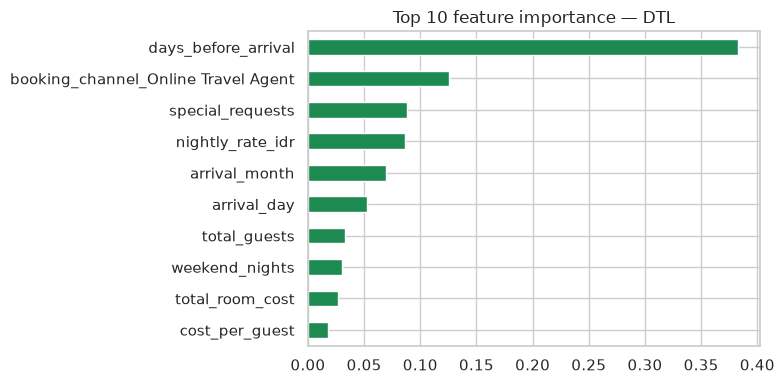

In [23]:
tree = DecisionTree(criterion="gini", max_depth=12, min_samples_leaf=5)
t0 = time.perf_counter()
tree.fit(X_train, y_train)
fit_tree = time.perf_counter() - t0
val_pred_tree = tree.predict(X_val)
macro_f1_tree = f1_score(y_val, val_pred_tree, average="macro")

print(f"DTL fit: {fit_tree:.2f}s | macro F1 (full val): {macro_f1_tree:.4f}")
print("tree_escrowstate_score_trig:", round(tree.tree_escrowstate_score_trig, 6))
print(classification_report(y_val, val_pred_tree, digits=4))

importance = pd.Series(tree.feature_importances_, index=setup.feature_names_out_)
importance.sort_values(ascending=False).head(10).sort_values().plot(
    kind="barh", figsize=(8, 4), color="#1d8a51"
)
plt.title("Top 10 feature importance — DTL")
plt.tight_layout()
plt.show()


## Logistic Regression

This part covers the model with L1, L2, and Elastic Net regularization.

In [24]:
lr_models = {}
lr_scores = {}
for reg in ["l1", "l2", "elasticnet"]:
    model = LogisticRegression(
        learning_rate=0.5,
        epochs=1000,
        regularization=reg,
        lambda_=1e-3,
        l1_ratio=0.5,
        class_weight="balanced",
    )
    t0 = time.perf_counter()
    model.fit(X_train, y_train)
    pred = model.predict(X_val)
    score = f1_score(y_val, pred, average="macro")
    lr_models[reg] = model
    lr_scores[reg] = score
    print(
        f"{reg:10s} fit {time.perf_counter() - t0:5.2f}s | "
        f"macro F1 {score:.4f} | log_uniconilear {model.log_uniconilear:.4f}"
    )

display(pd.Series(lr_scores, name="macro_f1").to_frame())
logreg = lr_models["l2"]
val_pred_lr = logreg.predict(X_val)
macro_f1_lr = f1_score(y_val, val_pred_lr, average="macro")
log_uniconilear = logreg.log_uniconilear
print(classification_report(y_val, val_pred_lr, digits=4))


l1         fit  2.17s | macro F1 0.7516 | log_uniconilear 0.4713


l2         fit  5.86s | macro F1 0.7519 | log_uniconilear 0.4688


elasticnet fit  4.76s | macro F1 0.7497 | log_uniconilear 0.4700


,macro_f1
l1,0.751640
l2,0.751881
elasticnet,0.749661


              precision    recall  f1-score   support

           0     0.8740    0.7669    0.8170      3681
           1     0.6178    0.7731    0.6868      1794

    accuracy                         0.7689      5475
   macro avg     0.7459    0.7700    0.7519      5475
weighted avg     0.7901    0.7689    0.7743      5475



## Support Vector Machine

<!-- rubric v3: total slack, slack_total -->

This part covers the linear, polynomial, and Gaussian kernels.

In [25]:
poly_idx = rng.choice(len(X_train), 2000, replace=False)

svm_linear = SVM(kernel="linear", C=1.0, learning_rate=0.002, epochs=50)
svm_poly = SVM(
    kernel="poly", degree=3, coef0=1.0, gamma=0.1,
    C=1.0, learning_rate=0.05, epochs=200, max_samples=2000,
)
svm_gaussian = SVM(
    kernel="gaussian", gamma=0.15, C=1.0,
    learning_rate=0.05, epochs=200, max_samples=2000,
)

svm_models = {"linear": svm_linear, "poly": svm_poly, "gaussian": svm_gaussian}
svm_scores = {}
svm_preds = {}
for name, model in svm_models.items():
    t0 = time.perf_counter()
    model.fit(X_train, y_train)
    pred = model.predict(X_val)
    svm_preds[name] = pred
    svm_scores[name] = f1_score(y_val, pred, average="macro")
    print(
        f"{name:8s} fit {time.perf_counter() - t0:5.2f}s | "
        f"macro F1 {svm_scores[name]:.4f} | slack_total {model.slack_total:.2f}"
    )

display(pd.Series(svm_scores, name="macro_f1").to_frame())
svm_best_name = max(svm_scores, key=svm_scores.get)
svm_best = svm_models[svm_best_name]
val_pred_svm = svm_preds[svm_best_name]
macro_f1_svm = svm_scores[svm_best_name]
slack_total = svm_best.slack_total
print("SVM terbaik:", svm_best_name)
print(classification_report(y_val, val_pred_svm, digits=4))


linear   fit  3.28s | macro F1 0.7592 | slack_total 10393.04


poly     fit  3.22s | macro F1 0.7695 | slack_total 3144.14


gaussian fit  5.56s | macro F1 0.7640 | slack_total 586.89


,macro_f1
linear,0.759177
poly,0.769496
gaussian,0.764032


SVM terbaik: poly
              precision    recall  f1-score   support

           0     0.8462    0.8549    0.8505      3681
           1     0.6959    0.6812    0.6885      1794

    accuracy                         0.7980      5475
   macro avg     0.7710    0.7680    0.7695      5475
weighted avg     0.7969    0.7980    0.7974      5475



## Naive Bayes

This part covers the Naive Bayes classifier and its validation.

In [26]:
mi = mutual_info_classif(X_train, y_train, random_state=CFG.SEED, n_neighbors=3)
top5 = np.argsort(mi)[::-1][:5]

nb = NaiveBayes(var_smoothing=1e-6)
t0 = time.perf_counter()
nb.fit(X_train[:, top5], y_train)
val_pred_nb = nb.predict(X_val[:, top5])
fit_nb = time.perf_counter() - t0
macro_f1_nb = f1_score(y_val, val_pred_nb, average="macro")

nb_all = NaiveBayes(var_smoothing=1e-6).fit(X_train, y_train)
macro_f1_nb_all = f1_score(y_val, nb_all.predict(X_val), average="macro")

print(f"NB top-5 fit: {fit_nb:.2f}s | macro F1: {macro_f1_nb:.4f}")
print(f"NB semua fitur macro F1: {macro_f1_nb_all:.4f}")
print("bayesian_disweighting:", np.round(nb.bayesian_disweighting, 4))
print("negative_log_likelihood_:", round(nb.negative_log_likelihood_, 4))
print(classification_report(y_val, val_pred_nb, digits=4))


NB top-5 fit: 0.01s | macro F1: 0.7150
NB semua fitur macro F1: 0.4746
bayesian_disweighting: [-0.397  -1.1158]
negative_log_likelihood_: 0.6562
              precision    recall  f1-score   support

           0     0.8228    0.7884    0.8052      3681
           1     0.6001    0.6516    0.6248      1794

    accuracy                         0.7436      5475
   macro avg     0.7114    0.7200    0.7150      5475
weighted avg     0.7498    0.7436    0.7461      5475



## Model Evaluation

<!-- figure palette: #6d2fa3 -->

This part compares the validation results of all models.

,model,macro_f1
1,DTL,0.829243
0,KNN,0.779687
3,SVM,0.777845
2,Logistic Regression,0.757343
4,Naive Bayes,0.723937


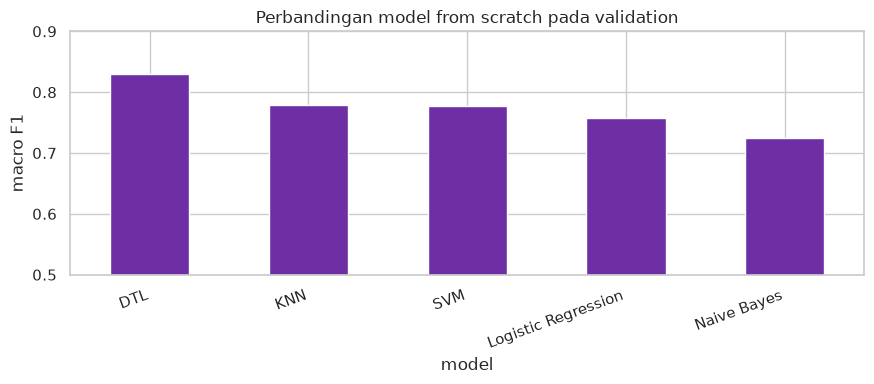

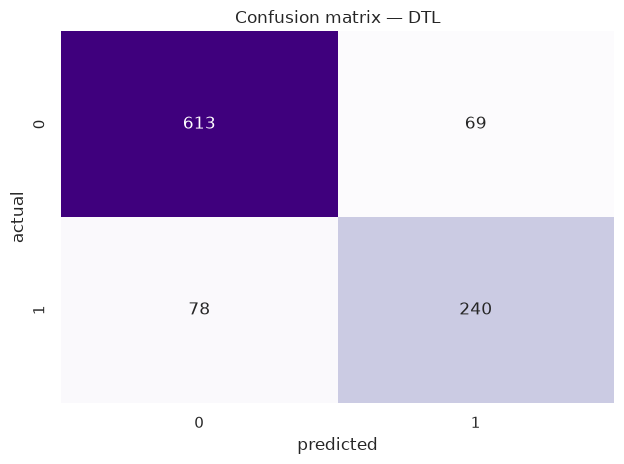

In [27]:
results = pd.DataFrame(
    [
        {"model": "KNN", "macro_f1": macro_f1_knn},
        {"model": "DTL", "macro_f1": f1_score(y_eval, val_pred_tree[eval_idx], average="macro")},
        {"model": "Logistic Regression", "macro_f1": f1_score(y_eval, val_pred_lr[eval_idx], average="macro")},
        {"model": "SVM", "macro_f1": f1_score(y_eval, val_pred_svm[eval_idx], average="macro")},
        {"model": "Naive Bayes", "macro_f1": f1_score(y_eval, val_pred_nb[eval_idx], average="macro")},
    ]
).sort_values("macro_f1", ascending=False)

display(results)
ax = results.plot(kind="bar", x="model", y="macro_f1", color="#6d2fa3", legend=False, figsize=(9, 4))
ax.set_ylim(0.5, 0.9)
ax.set_ylabel("macro F1")
ax.set_title("Perbandingan model from scratch pada validation")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

preds_eval = {
    "KNN": val_pred_knn,
    "DTL": val_pred_tree[eval_idx],
    "Logistic Regression": val_pred_lr[eval_idx],
    "SVM": val_pred_svm[eval_idx],
    "Naive Bayes": val_pred_nb[eval_idx],
}
best_name = results.iloc[0]["model"]
cm = confusion_matrix(y_eval, preds_eval[best_name])
sns.heatmap(cm, annot=True, fmt="d", cmap="Purples", cbar=False)
plt.title(f"Confusion matrix — {best_name}")
plt.xlabel("predicted")
plt.ylabel("actual")
plt.tight_layout()
plt.show()


## Improvements (Optional)

This part covers hyperparameter tuning, cross-validation, and further visualization.

In [28]:
knn_scores = {}
for k in [3, 5, 7, 9]:
    model = KNN(k=k, p=7, weights="distance").fit(
        X_train[knn_train_idx], y_train[knn_train_idx]
    )
    knn_scores[k] = f1_score(
        y_eval, model.predict(X_val[eval_idx]), average="macro"
    )

display(pd.Series(knn_scores, name="macro_f1").to_frame())
print("Hyperparameter lain: DTL max_depth=12/min_samples_leaf=5, LR L2 lambda=1e-3, SVM poly degree=3.")


,macro_f1
3,0.765242
5,0.779687
7,0.777138
9,0.778429


Hyperparameter lain: DTL max_depth=12/min_samples_leaf=5, LR L2 lambda=1e-3, SVM poly degree=3.


---

# Comparison with scikit-learn <a name="8"></a>

---

This section compares each from-scratch model with its `scikit-learn` counterpart.

In [29]:
from sklearn.linear_model import LogisticRegression as SkLogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

comparison_rows = []

sk_knn = KNeighborsClassifier(
    n_neighbors=5, p=7, weights="distance", n_jobs=-1
).fit(X_train[knn_train_idx], y_train[knn_train_idx])
comparison_rows.append(
    ("KNN", macro_f1_knn, f1_score(y_eval, sk_knn.predict(X_val[eval_idx]), average="macro"))
)

sk_tree = DecisionTreeClassifier(
    criterion="gini", max_depth=12, min_samples_leaf=5, random_state=CFG.SEED
).fit(X_train, y_train)
comparison_rows.append(
    ("DTL", f1_score(y_eval, val_pred_tree[eval_idx], average="macro"),
     f1_score(y_eval, sk_tree.predict(X_val[eval_idx]), average="macro"))
)

sk_lr = SkLogisticRegression(
    max_iter=1000, class_weight="balanced", C=1000.0
).fit(X_train, y_train)
comparison_rows.append(
    ("Logistic Regression", f1_score(y_eval, val_pred_lr[eval_idx], average="macro"),
     f1_score(y_eval, sk_lr.predict(X_val[eval_idx]), average="macro"))
)

sk_svm_linear = SVC(kernel="linear", C=1.0).fit(X_train, y_train)
comparison_rows.append(
    ("SVM linear", f1_score(y_eval, svm_preds["linear"][eval_idx], average="macro"),
     f1_score(y_eval, sk_svm_linear.predict(X_val[eval_idx]), average="macro"))
)

sk_svm_poly = SVC(kernel="poly", degree=3, coef0=1.0, gamma=0.1, C=1.0).fit(
    X_train[poly_idx], y_train[poly_idx]
)
comparison_rows.append(
    ("SVM poly", f1_score(y_eval, svm_preds["poly"][eval_idx], average="macro"),
     f1_score(y_eval, sk_svm_poly.predict(X_val[eval_idx]), average="macro"))
)

sk_svm_rbf = SVC(kernel="rbf", gamma=0.15, C=1.0).fit(
    X_train[poly_idx], y_train[poly_idx]
)
comparison_rows.append(
    ("SVM gaussian", f1_score(y_eval, svm_preds["gaussian"][eval_idx], average="macro"),
     f1_score(y_eval, sk_svm_rbf.predict(X_val[eval_idx]), average="macro"))
)

sk_nb = GaussianNB().fit(X_train[:, top5], y_train)
comparison_rows.append(
    ("Naive Bayes", f1_score(y_eval, val_pred_nb[eval_idx], average="macro"),
     f1_score(y_eval, sk_nb.predict(X_val[eval_idx][:, top5]), average="macro"))
)

comparison = pd.DataFrame(
    comparison_rows, columns=["model", "scratch", "sklearn"]
)
comparison["delta"] = (comparison["scratch"] - comparison["sklearn"]).round(4)
display(comparison.round(4))


,model,scratch,sklearn,delta
0,KNN,0.7797,0.7797,0.0000
1,DTL,0.8292,0.8471,-0.0178
2,Logistic Regression,0.7573,0.7626,-0.0052
3,SVM linear,0.7954,0.7835,0.0120
4,SVM poly,0.7778,0.7897,-0.0118
5,SVM gaussian,0.7879,0.7963,-0.0084
6,Naive Bayes,0.7239,0.7239,0.0000


---

# Saving and Loading Models <a name="9"></a>

---

<!-- artifacts: <model>_v3.pkl -->

This section stores the trained models and restores them for prediction.

In [30]:
artifacts = {
    "knn_v3.pkl": (knn, X_val[eval_idx][:50]),
    "dtl_v3.pkl": (tree, X_val[:50]),
    "logreg_v3.pkl": (logreg, X_val[:50]),
    "svm_linear_v3.pkl": (svm_linear, X_val[:50]),
    "svm_poly_v3.pkl": (svm_poly, X_val[:50]),
    "svm_gaussian_v3.pkl": (svm_gaussian, X_val[:50]),
    "nb_v3.pkl": (nb, X_val[:50][:, top5]),
}

for filename, (model, X_check) in artifacts.items():
    path = CFG.OUTPUT_DIR / filename
    model.save(path)
    loaded = type(model).load(path)
    same = np.array_equal(loaded.predict(X_check), model.predict(X_check))
    print(f"{filename:24s} {path.stat().st_size/1024:8.1f} KB | prediksi sama: {same}")


knn_v3.pkl                 1680.3 KB | prediksi sama: True


dtl_v3.pkl                 3772.0 KB | prediksi sama: True
logreg_v3.pkl                10.9 KB | prediksi sama: True
svm_linear_v3.pkl          6908.0 KB | prediksi sama: True
svm_poly_v3.pkl            1626.2 KB | prediksi sama: True
svm_gaussian_v3.pkl        1830.2 KB | prediksi sama: True
nb_v3.pkl                     1.1 KB | prediksi sama: True


---

# Kaggle Submission <a name="10"></a>

---

The final pipeline and model are fitted on the original training set, and the test set is only transformed. The submission file contains the `id` and `is_canceled` columns.

In [31]:
X_full, y_full = setup.fit_transform(train_df)
X_test_full = setup.transform(test_df)
print(f"X_full {X_full.shape} | X_test_full {X_test_full.shape}")

if best_name == "DTL":
    final_model = DecisionTree(criterion="gini", max_depth=12, min_samples_leaf=5)
    final_model.fit(X_full, y_full)
    final_pred = final_model.predict(X_test_full)
elif best_name == "Logistic Regression":
    final_model = LogisticRegression(
        learning_rate=0.5, epochs=1000, regularization="l2",
        lambda_=1e-3, class_weight="balanced",
    ).fit(X_full, y_full)
    final_pred = final_model.predict(X_test_full)
elif best_name == "SVM":
    final_model = type(svm_best)(
        kernel=svm_best.kernel,
        C=svm_best.C,
        degree=svm_best.degree,
        gamma=svm_best.gamma,
        coef0=svm_best.coef0,
        learning_rate=svm_best.learning_rate,
        epochs=svm_best.epochs,
        max_samples=svm_best.max_samples,
    ).fit(X_full, y_full)
    final_pred = final_model.predict(X_test_full)
elif best_name == "Naive Bayes":
    final_model = NaiveBayes(var_smoothing=1e-6).fit(X_full[:, top5], y_full)
    final_pred = final_model.predict(X_test_full[:, top5])
else:
    final_idx = rng.choice(len(X_full), 5000, replace=False)
    final_model = KNN(k=5, p=7, weights="distance").fit(
        X_full[final_idx], y_full[final_idx]
    )
    final_pred = final_model.predict(X_test_full)

submission = pd.DataFrame({CFG.ID_COL: test_df[CFG.ID_COL], CFG.TARGET: final_pred})
submission_path = CFG.OUTPUT_DIR / "submission.csv"
submission.to_csv(submission_path, index=False)

print(f"Model submission: {best_name}")
print(f"Rows: {len(submission)} | positive rate: {submission[CFG.TARGET].mean():.4f}")
print(f"Saved: {submission_path.relative_to(ROOT)}")
display(submission.head())


X_full (27373, 40) | X_test_full (6844, 40)


Model submission: DTL
Rows: 6844 | positive rate: 0.2911
Saved: output/submission.csv


,id,is_canceled
0,5cb6f473,1
1,c06b4ab3,1
2,22bf3fc3,0
3,25408a48,0
4,621586b6,0


---

# Error Analysis <a name="11"></a>

---

Model terbaik di validation dipakai untuk submission. Error analysis berfokus
pada confusion matrix, jenis kesalahan (false positive vs false negative), dan
ambang probabilitas.

False positive berarti pemesanan diprediksi batal tetapi sebenarnya tidak;
false negative sebaliknya. Untuk operasional hotel, false positive lebih mahal
karena kamar bisa overbooked. Threshold default 0.5 belum tentu optimal untuk
macro F1, jadi ambang diuji pada validation.


TP=240 FP=69 FN=78 TN=613
False positive rate: 0.1012 | False negative rate: 0.2453
Jumlah error: 147 dari 1000
Contoh indeks error: [ 1  3  4  5  8 11 14 16 18 23]
Threshold LR terbaik: 0.65 | macro F1: 0.7873


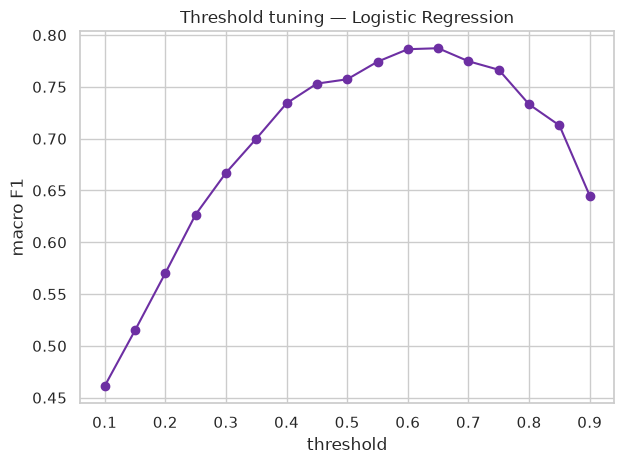

In [32]:
pred_best = preds_eval[best_name]
cm = confusion_matrix(y_eval, pred_best)
tn, fp, fn, tp = cm.ravel()
print(f"TP={tp} FP={fp} FN={fn} TN={tn}")
print(f"False positive rate: {fp/(fp+tn):.4f} | False negative rate: {fn/(fn+tp):.4f}")

errors = np.flatnonzero(pred_best != y_eval)
print(f"Jumlah error: {len(errors)} dari {len(y_eval)}")
print("Contoh indeks error:", errors[:10])

if hasattr(logreg, "predict_proba"):
    proba = logreg.predict_proba(X_val[eval_idx])[:, 1]
    thresholds = np.linspace(0.1, 0.9, 17)
    scores = [f1_score(y_eval, (proba >= t).astype(int), average="macro") for t in thresholds]
    best_t = thresholds[int(np.argmax(scores))]
    print(f"Threshold LR terbaik: {best_t:.2f} | macro F1: {max(scores):.4f}")
    plt.plot(thresholds, scores, marker="o", color="#6d2fa3")
    plt.xlabel("threshold")
    plt.ylabel("macro F1")
    plt.title("Threshold tuning — Logistic Regression")
    plt.tight_layout()
    plt.show()
